# Example of the AiTLAS toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import RoadNetDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import ResizeToTensor

## Visualize images and masks

Total number of patches: 20


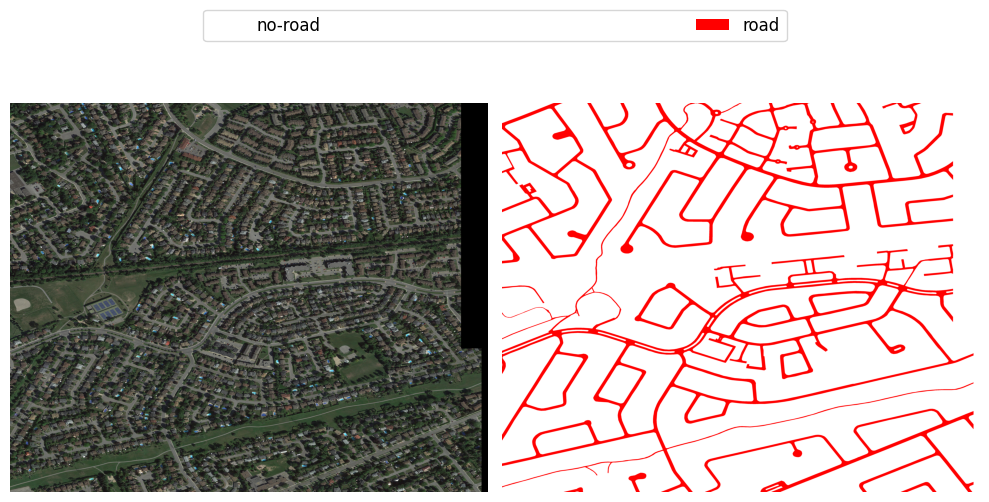

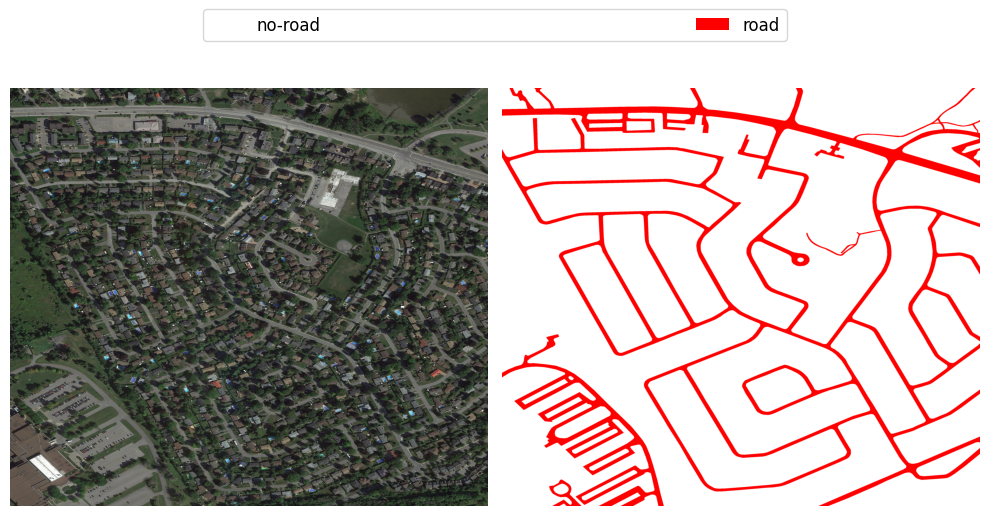

In [ ]:
dataset_config = {
    "data_dir": "./data/RoadNet/"
}
dataset = RoadNetDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(15);

In [5]:
dataset.data_distribution_table()

,Number of pixels
no-road,170130098.0
road,27550476.0


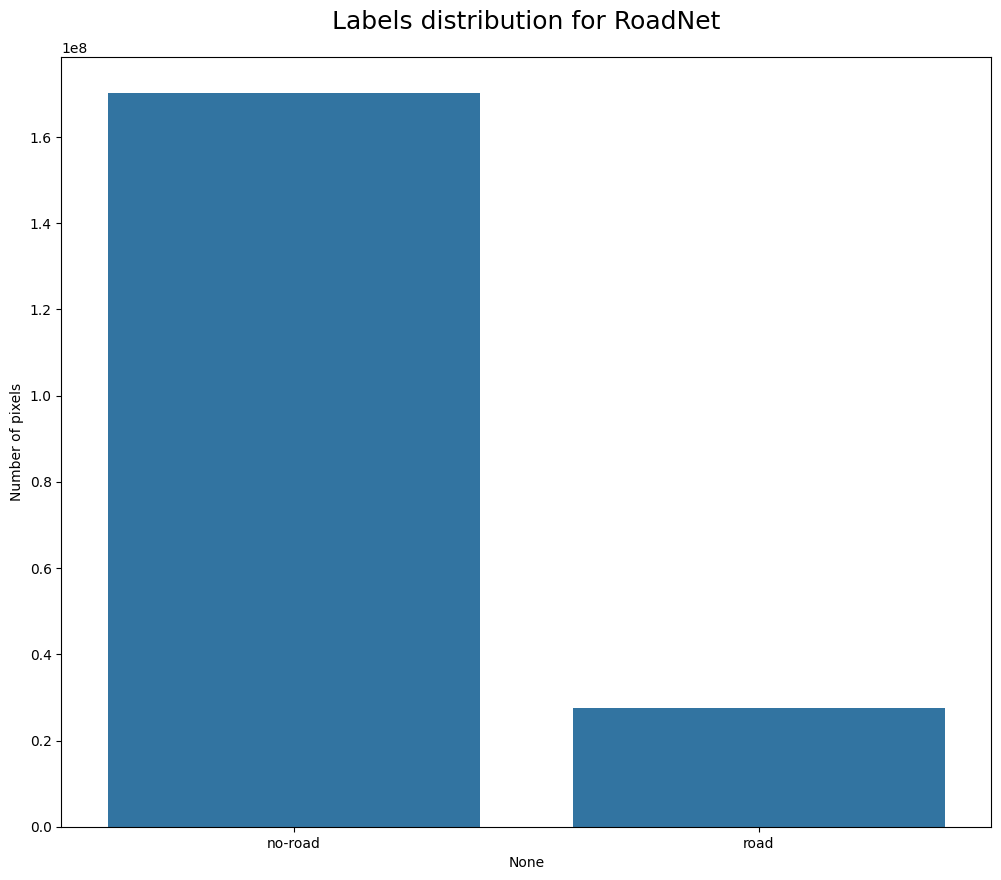

In [6]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/RoadNet",
    "csv_file": "./data/RoadNet/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = RoadNetDataset(train_dataset_config)
len(train_dataset)

16

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/RoadNet"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [9]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-03-18 08:34:35,654 INFO Starting training.
training: 100%|██████████| 4/4 [07:00<00:00, 105.01s/it]
2025-03-18 08:41:35,792 INFO epoch: 1, time: 420, loss:  0.55297
testing on train set: 100%|██████████| 4/4 [04:51<00:00, 72.98s/it] 
2025-03-18 08:46:29,361 INFO IOU:0.03448090166111711, IOU mean:0.03427189441802504, IOU per Class:[0.01037217 0.05817162]
training: 100%|██████████| 4/4 [04:51<00:00, 72.90s/it] 
2025-03-18 08:51:20,971 INFO epoch: 2, time: 291, loss:  0.53760
testing on train set: 100%|██████████| 4/4 [05:49<00:00, 87.35s/it] 
2025-03-18 08:57:10,398 INFO IOU:0.04150385341396848, IOU mean:0.04500479890410936, IOU per Class:[0.03018212 0.05982748]
training: 100%|██████████| 4/4 [06:23<00:00, 95.82s/it] 
2025-03-18 09:03:33,681 INFO epoch: 3, time: 383, loss:  0.52112
testing on train set: 100%|██████████| 4/4 [07:27<00:00, 111.98s/it]
2025-03-18 09:11:01,624 INFO IOU:0.11953959029591243, IOU mean:0.10314541309237266, IOU per Class:[0.14142515 0.06486568]
training: 100

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/RoadNet",
    "csv_file": "./data/RoadNet/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = RoadNetDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/RoadNet/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2


2025-03-18 10:48:42,888 INFO Loading checkpoint /home/dragik/data/FAIR_EO/RoadNet/checkpoint.pth.tar
2025-03-18 10:48:43,320 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/RoadNet/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 1/1 [03:00<00:00, 180.33s/it]


[{'IOU': 0.41953521339362476,
  'IOU mean': 0.29221756824754214,
  'IOU per Class': array([0.52151273, 0.06292241])}]

## Predictions

2025-03-18 11:22:32,719 INFO Loading checkpoint /home/dragik/data/FAIR_EO/RoadNet/checkpoint.pth.tar
2025-03-18 11:22:33,225 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/RoadNet/checkpoint.pth.tar at epoch 11


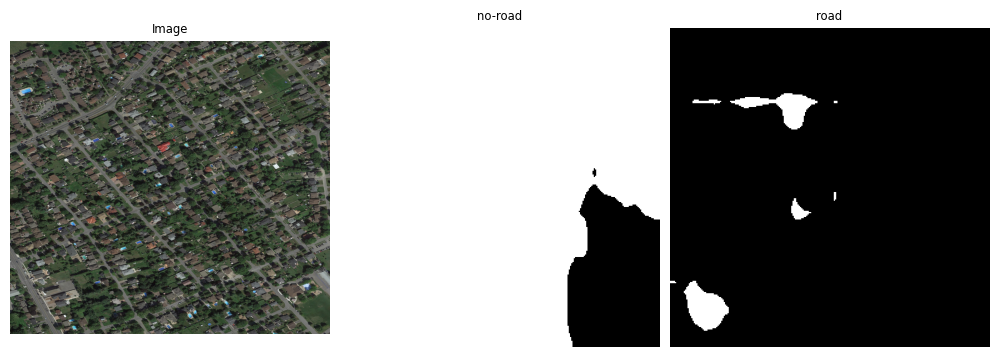

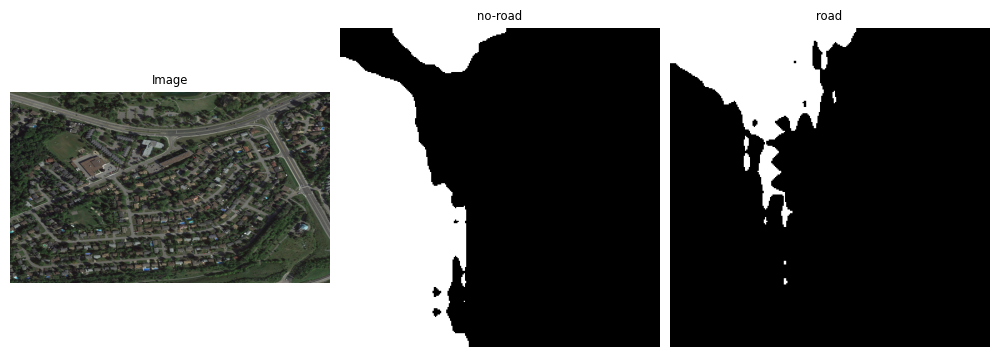

In [ ]:
model_path = "./data/RoadNet/checkpoint.pth.tar"
labels = ["no-road","road"]
transform = ResizeToTensor()
model.load_model(model_path)
plt.rcParams.update({'font.size': 7})
csv_file = "./data/RoadNet/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('./data/RoadNet/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/RoadNet/' + test_list[1])
fig = model.predict_masks(image, labels, transform)